# Nanoparticle Size Distribution Analysis

This notebook demonstrates the full workflow for analysing TEM images to obtain
nanoparticle size distributions, using the `SELENAtools` module.

It replaces the original `2023-06_TEM-distrib_1011_V2.ipynb` notebook and the
`TEMimg` / `TEMana` classes with clean function calls.

In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt

import SELENAtools as st

plt.rcParams.update({'font.size': 22})

## 1. Configuration

Set the root data path and sample definitions.  Adjust these to match your
local data layout.

In [2]:
# Data root — edit to point at your TEM data
root_path = r'Z:\RawData\TEM'

# Sample definitions (synthesis batch → sample name → relative folder path)
syntheses = {
    'SindaBatch': {
        'SS60': r'2023-07-18\SS60-Au45Cu55-D800',
    },
}

# Samples to analyse in this run
sample_list = ['SS60']

## 2. Process Each TEM Image

For every `.dm3` file matching the pattern, run the pipeline:
1. Load & normalize
2. Gaussian blur
3. Adaptive threshold
4. Extract particles
5. Save results

In [3]:
# Tunable parameters — adjust these to optimise segmentation
blur_kernel = 21
block_size = 351
offset = 20
cutoff_low = 2.0    # nm
cutoff_high = 10000.0  # nm

all_sizes = []  # collect sizes across all images for the final histogram

for sample in sample_list:
    to_analyse_path = os.path.join(root_path, syntheses['SindaBatch'][sample])
    dm3_files = st.find_dm3_files(to_analyse_path, pattern='60kX')

    for dm3_path in dm3_files:
        print(f'Processing: {dm3_path}')

        # Step 1: Load & normalize
        image, metadata = st.load_tem_image(dm3_path)

        # Step 2: Gaussian blur
        blurred = st.apply_gaussian_blur(image, kernel_size=blur_kernel)

        # Step 3: Adaptive threshold
        binary_mask = st.adaptive_threshold(blurred, block_size=block_size, offset=offset)

        # Step 4: Extract particles
        sizes, contours = st.extract_particles(
            binary_mask,
            calibration_nm=metadata['calib'],
            cutoff_low=cutoff_low,
            cutoff_high=cutoff_high,
        )

        # Step 5: Create overlay & save
        overlay = st.create_overlay(blurred, contours)
        dm3_basename = os.path.basename(dm3_path)
        params = st.segmentation_info(block_size, offset, cutoff_low, cutoff_high)
        params['blur'] = f'kernel={blur_kernel}'

        parent_folder = os.path.dirname(dm3_path)
        st.save_single_image_results(
            parent_folder, dm3_basename, sizes, params, overlay
        )

        all_sizes.extend(sizes)
        print(f'  → {len(sizes)} particles found')

print(f'\nTotal particles across all images: {len(all_sizes)}')

Processing: Z:\RawData\TEM\2023-07-18\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0001.dm3
  → 8 particles found
Processing: Z:\RawData\TEM\2023-07-18\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0003.dm3
  → 16 particles found
Processing: Z:\RawData\TEM\2023-07-18\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0004.dm3
  → 10 particles found
Processing: Z:\RawData\TEM\2023-07-18\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0005.dm3
  → 12 particles found
Processing: Z:\RawData\TEM\2023-07-18\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0006.dm3
  → 7 particles found
Processing: Z:\RawData\TEM\2023-07-18\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0007.dm3
  → 4 particles found
Processing: Z:\RawData\TEM\2023-07-18\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0008.dm3
  → 4 particles found
Processing: Z:\RawData\TEM\2023-07-18\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0009.dm3
  → 9 particles found
Processing: Z:\RawData\TEM\2023-07-18\SS60-Au45Cu55-D800\60kX-SS60-Au45Cu55-D800-0010.dm3
  → 8 parti

## 3. Aggregate Results & Plot Histogram

Combine all particle sizes from the analysed images and plot the size
distribution with a Gaussian fit.

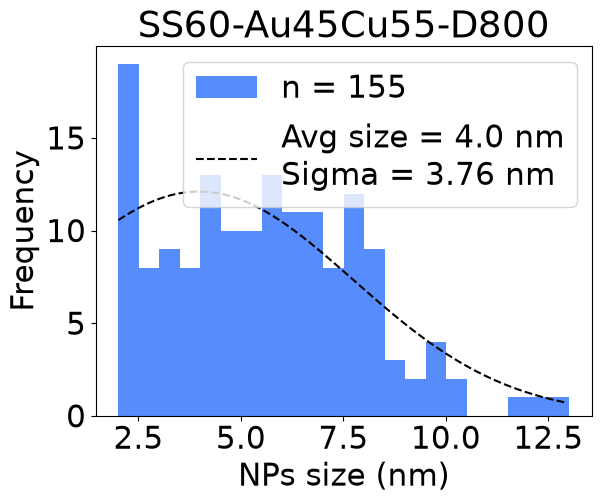

Fitted Gaussian: mean = 3.98 nm, sigma = 3.76 nm


In [4]:
binwidth = 0.5
sample_name = 'SS60-Au45Cu55-D800'

sizes_array = np.array(all_sizes)
popt, pcov = st.plot_histogram(
    sizes_array, binwidth=binwidth, fit_gaussian_flag=True, title=sample_name
)
plt.show()

if popt is not None:
    print(f'Fitted Gaussian: mean = {popt[1]:.2f} nm, sigma = {popt[2]:.2f} nm')

## 4. Save Final Results

Write the combined size data, processing parameters, and histogram PDF to the
`analysis/` folder.

In [5]:
to_analyse_path = os.path.join(root_path, syntheses['SindaBatch'][sample_list[0]])
analysis_dir = st.ensure_analysis_dir(to_analyse_path)

final_params = st.segmentation_info(block_size, offset, cutoff_low, cutoff_high)
final_params['blur'] = f'kernel={blur_kernel}'

pdf_path = st.save_results(
    analysis_dir, all_sizes, final_params, sample_name, binwidth=binwidth
)
print(f'Results saved to: {pdf_path}')

Results saved to: Z:\RawData\TEM\2023-07-18\SS60-Au45Cu55-D800\analysis\result.pdf


## 5. (Optional) Re-read Saved Results

If you already ran the pipeline earlier, you can re-read the `.hist` files
from the `analysis/` folder without re-processing images.

In [ ]:
analysis_dir = os.path.join(to_analyse_path, 'analysis')
df, file_names = st.read_hist_files(analysis_dir)
print(f'Read {len(file_names)} .hist files, {len(df)} total particles')
df.head()